## Numerical solution to the QHO (Quantum Harmonic Oscillator)

Version October 2026 using *solve_ivp* instead of *odeint*

In [1]:
%pylab inline
from IPython.display import Image

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, simpson
from scipy.optimize import brentq

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In this notebook we show how to find numerical solutions for the wave function of energy eigenstates for the time independent Schrödinger equation in one dimensions.

The integration is illustrate by running the script *new_harm_osc_integration.py* which calculates numerically the energy eigenstates for a quantum harmonic oscillator.

By changing the function fct() in the python script you can find numerical solutions for other symmetric potentials $V(-x)=V(x)$. See cell below for more details.

If the potential is not symmetric you need to have a more systematic approach to find the numerical solutions and modify the initial conditions in the script. The initial conditions in this script work only for even or odd solutions for symmetric potentials.


#### How to use a notebook for your projects

You should edit your script, for example with spyder, and run the code from a notebook cell. The notebook can then be used to enter text explaining what you are calculating with your codes. The 

Output of the codes is automatically recorded in notebook, and you can then type in your discussion of the numerical data.

# Quantum Harmonic Oscillator

The code in the script *harm_osc_integration.py* integrates numerically 

$\psi'' = \frac{2m}{\hbar^2}(V(x) - E)\psi$

for the potential $V(x)=\frac12 m \omega^2 x^2$.

The right-hand of the Schrödinger equation is the second element of the list returned by fct() in *harm_osc_integration.py*

The *x* and *energy* in fct() are the dimensionless variables:

$x \to \zeta = \sqrt{\frac{2m\omega}{\hbar}} x$

$E \to \epsilon = \frac{E}{\hbar \omega}$

Using dimensionless variables ensures that the numbers during the
numerical integration are neither too small nor too larger to minimise numerical errors.

## The *new_harm_osc_integration.py* script

Move to the directory where the script *new_harm_osc_integration.py*
and run it from a jupyter cell:

run new_harm_osc_integration.py

The script will ask you:

1. if the eigenfunction is even or odd
 
2. the maximum value of x [default is 8]

3. what is the # of integration steps [default is 2001]?  

4. The initial lowest bracket energy

5. The initial highest bracket energy

The energy of the energy eigenstate must be inside this energy interval. If you do not know the analytical solution for the quantum system you are integrating, you will have to use 'educated' guess work, till you find a solution.  Usually it is better to start by searching the numerical solution of the ground state.

The numerical solution is in the array *psi_low*. The
column [0] has the values of $\psi$ and [1] of $\psi'$. The corresponding $x$ values are in the array *x_range*.

Below we search for the numerical solutions of a quantum harmonic oscillator.

In [2]:
%matplotlib inline

In [2]:
pwd

'/Users/fil/Library/CloudStorage/Dropbox/0-COURSES/31-QM/Python/Py_-_Wave_Function_Integration'

In [4]:
run new_harm_osc_integration.py

'even' or 'odd' eigenfunction?  even
What is the max value of x [8]?  
What is the # of integration steps [2001]?  
Low bracket energy  0
High bracket energy  0.4


ValueError: The residuals do not bracket a root. Choose different energy bounds.

No energy eigenstate was found within the bracketing values used for this run.

The energy of the ground state in the dimensionless units used in the script is 0.5. This is why the initial guess above did not work.

'even' or 'odd' eigenfunction?  even
What is the max value of x [8]?  
What is the # of integration steps [2001]?  
Low bracket energy  0
High bracket energy  0.8


Ground state energy: E = 0.5000000001
psi(0) = 1.000e+00


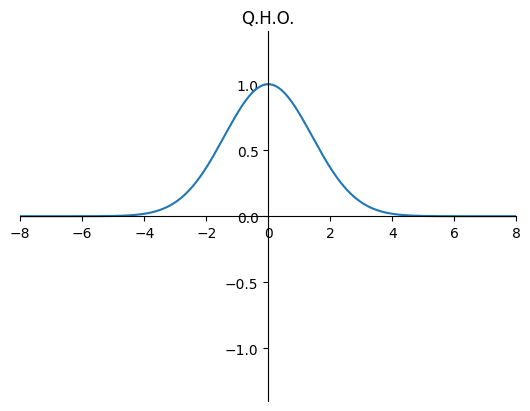

<Figure size 640x480 with 0 Axes>

In [5]:
run new_harm_osc_integration.py


In the next cell displays the data in the array *psi_low*, which
is numerical solution for the ground state.

The left column has the values $\Psi$ for the range $[0,x_\rm{max}]$. The integration is from 0 to $x_\rm{max}$ only. The plot for the negative values of $x$ is done using the symmetry of the wave function. The corresponding values of $x$ are in the array $x_\rm{range}$. 

Have a look at the script to see how the plot is done.

'even' or 'odd' eigenfunction?  odd
What is the max value of x [8]?  
What is the # of integration steps [2001]?  
Low bracket energy  1
High bracket energy  1.7


Ground state energy: E = 1.5000000001
psi(0) = 0.000e+00


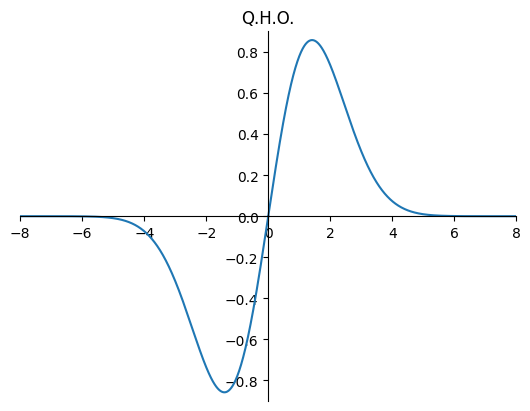

<Figure size 640x480 with 0 Axes>

In [10]:
run new_harm_osc_integration.py

Next we calculate the numerical solution for the level $n=8$.

'even' or 'odd' eigenfunction?  even
What is the max value of x [8]?  
What is the # of integration steps [2001]?  
Low bracket energy  6
High bracket energy  6.8


Ground state energy: E = 6.5000035771
psi(0) = 1.000e+00


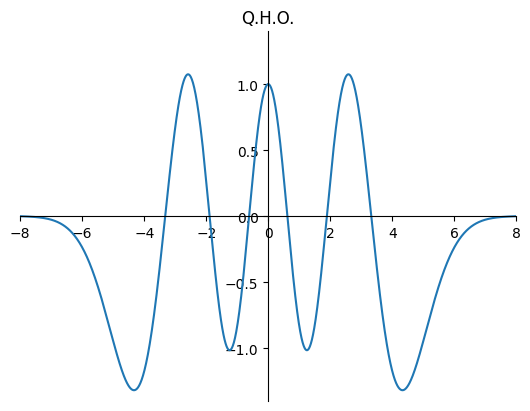

In [57]:
run 'new_harm_osc_integration.py'

'even' or 'odd' eigenfunction?  even
What is the max value of x [8]?  10
What is the # of integration steps [2001]?  
Low bracket energy  8
High bracket energy  8.6


Ground state energy: E = 8.5000000007
psi(0) = 1.000e+00


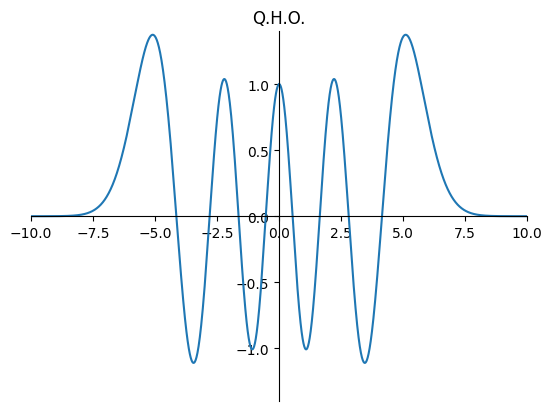

<Figure size 640x480 with 0 Axes>

In [7]:
run new_harm_osc_integration.py

In this case in order to obtain better data we need to use a higher *x_max*.

'even' or 'odd' eigenfunction?  odd
What is the max value of x [8]?  10
What is the # of integration steps [2001]?  
Low bracket energy  11
High bracket energy  11.8


Ground state energy: E = 11.5000000839
psi(0) = 0.000e+00


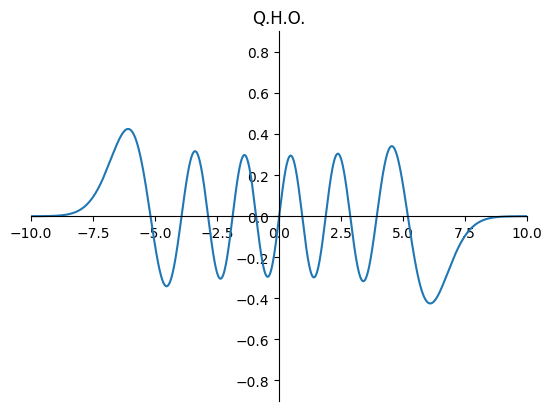

<Figure size 640x480 with 0 Axes>

In [11]:
run new_harm_osc_integration.py

The values of $\psi$ above look quite good up to $|x|<10$.

'even' or 'odd' eigenfunction?  even
What is the max value of x [8]?  10
What is the # of integration steps [2001]?  
Low bracket energy  12
High bracket energy  12.9


Ground state energy: E = 12.5000005128
psi(0) = 1.000e+00


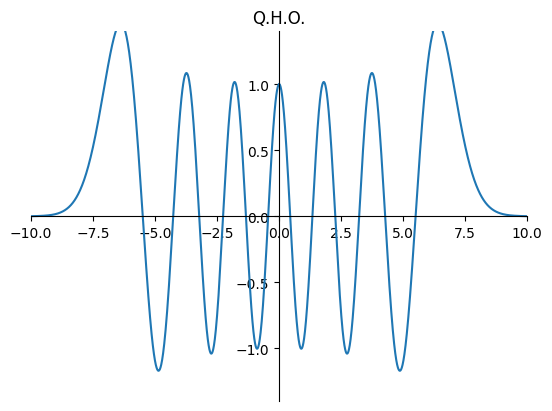

<Figure size 640x480 with 0 Axes>

In [12]:
run new_harm_osc_integration.py

Shooting energy: E = -42.2494915386
psi(0) = 2.899e-13


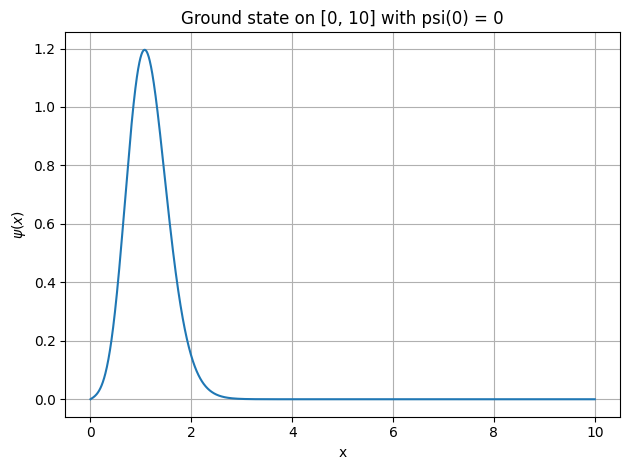

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, simpson
from scipy.optimize import brentq

D = 7.0**2
x_start, x_end = 10.0, 0.0

def U(x):
    return D * (
        np.exp(-2.0 * (x - 1.0))
        - 2.0 * np.exp(-(x - 1.0))
    )

psi_start =   0.000001
#dpsi_start = -np.sqrt(-E) * psi_start

def integrate_for_energy(E, x_eval):
    """Integrate inward from x=10 for a trial energy E."""
    if E >= 0:
        raise ValueError("A bound-state trial energy must be negative.")

    # Asymptotic decaying-tail initial conditions at x=10.
    #psi_start =   0.000001
    dpsi_start = -np.sqrt(-E) * psi_start

    def rhs(x, psi):
        return [psi[1], (U(x) - E) * psi[0]]

    sol = solve_ivp(
        rhs,
        (x_start, x_end),
        [psi_start, dpsi_start],
        t_eval=x_eval,
        method="DOP853",
        rtol=1e-9,
        atol=1e-11,
    )
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol

def shooting_residual(E):
    """Residual for the hard-wall condition psi(0) = 0."""
    sol = integrate_for_energy(E, [x_end])
    return sol.y[0, -1]

# Lower and upper trial energies; both must be negative.
E_lower = -42.3
E_upper = -42.0

f_lower = shooting_residual(E_lower)
f_upper = shooting_residual(E_upper)
if f_lower * f_upper >= 0:
    raise ValueError(
        "The residuals do not bracket a root. Choose different energy bounds."
    )

# bracketing 
E_ground = brentq(shooting_residual, E_lower, E_upper, xtol=1e-10, )

# Integrate once more at the found energy to obtain the wavefunction.
x_descending = np.linspace(x_start, x_end, 2001)

sol = integrate_for_energy(E_ground, x_descending)

# Reverse arrays so x increases from 0 to 10, then normalize.
x = sol.t[::-1]
psi = sol.y[0, ::-1]
psi /= np.sqrt(simpson(psi**2, x=x))

print(f"Shooting energy: E = {E_ground:.10f}")
print(f"psi(0) = {psi[0]:.3e}")

plt.plot(x, psi)
plt.xlabel("x")
plt.ylabel(r"$\psi(x)$")
plt.title("Ground state on [0, 10] with psi(0) = 0")
plt.grid(True)
plt.tight_layout()
plt.show()


In [55]:
pwd

'/Users/fil/Library/CloudStorage/Dropbox/0-COURSES/31-QM/Python/Py_-_Wave_Function_Integration'

What is the max value of x [8]?  
What is the # of integration steps [2001]?  
Enter lambda [7]? 
Enter x_e [1]? 2
Low bracket energy  -42.3
High bracket energy  -42


Ground state energy: E = -42.2499999996
psi(0) = 1.000e-06


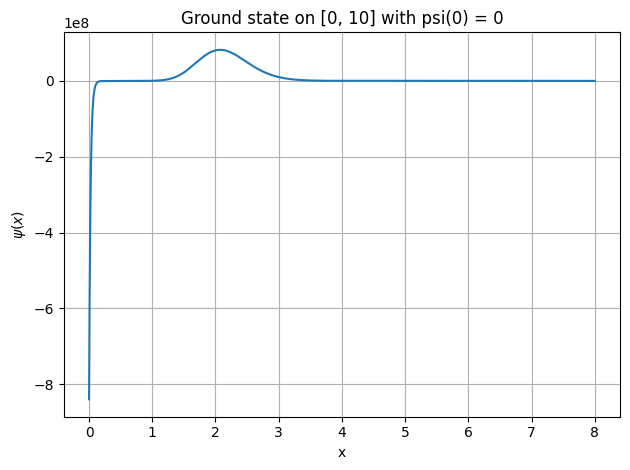

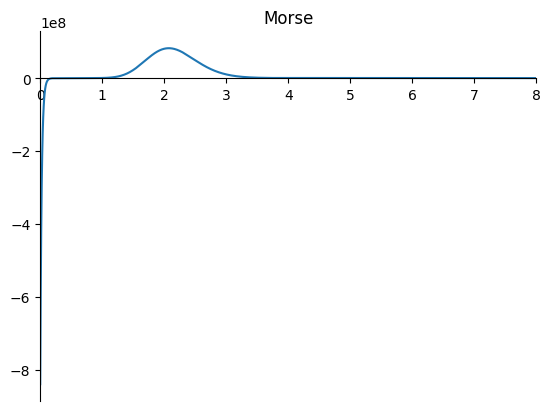

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, simpson
from scipy.optimize import brentq

# integration range and steps
#
xmax = float(input("What is the max value of x [8]? ") or 8)
steps = int(input("What is the # of integration steps [2001]? ") or 2001)
#
x_start, x_end = xmax, 0.0

# initial bracketing energy values these are narrowed by brentq
#
lam = float(input("Enter lambda [7]?") or 7)
x_e = float(input("Enter x_e [1]?") or 1)
en_low = float(input("Low bracket energy "))
en_up = float(input("High bracket energy "))

def U(x):
    return lam**2 * ( np.exp(-2.0 * (x - x_e)) - 2.0 * np.exp(-(x - x_e)) )

def integrate_for_energy(E, x_eval):
    """Integrate inward from x = 10 for a trial energy E."""
#    if E >= 0:
#        raise ValueError("A bound-state trial energy must be negative.")

    # Asymptotic decaying-tail initial conditions at x=10.
    #
    psi_start =   0.000001
    dpsi_start = -np.sqrt(-E) * psi_start

    def ode_rhs(x, psi):
        return [psi[1], (U(x) - E) * psi[0]]

    sol = solve_ivp(ode_rhs, (x_start, x_end), [psi_start, dpsi_start],
        t_eval=x_eval, method="DOP853", rtol=1e-9, atol=1e-11,)
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol

def shooting_residual(E):
    """Residual for the hard-wall condition psi(0) = 0."""
    sol = integrate_for_energy(E, [x_end])
    return sol.y[0, -1]

# Lower and upper trial energies; both must be negative.

f_lower = shooting_residual(en_low)
f_upper = shooting_residual(en_up)
if f_lower * f_upper >= 0:
    raise ValueError(
        "The residuals do not bracket a root. Choose different energy bounds."
    )

# bracketing 
en_value = brentq(shooting_residual, en_low, en_up, xtol=1e-10, )

# Integrate once more at the found energy to obtain the wavefunction.
x_range = np.linspace(x_start, x_end, steps)
#
sol = integrate_for_energy(en_value, x_range)

### printing ###
# Reverse arrays so x increases from 0 to 10, then normalize.
x = sol.t
psi = sol.y[0]
#psi /= np.sqrt(simpson(psi**2, x=x))

print(f"Ground state energy: E = {en_value:.10f}")
print(f"psi(0) = {psi[0]:.3e}")

plt.plot(x, psi)
plt.xlabel("x")
plt.ylabel(r"$\psi(x)$")
plt.title("Ground state on [0, 10] with psi(0) = 0")
plt.grid(True)
plt.tight_layout()
plt.show()

# start figure settings
fig, ax = plt.subplots()
#
ax.set_xlim([0, xmax])  # use xmax in the flat region for final plot
#ax.set_ylim([-1.4, 1.4])
ax.set_title('Morse');
#
ax.spines['right'].set_color('none') # no vertical right border
ax.spines['top'].set_color('none') # no top border
ax.spines['bottom'].set_position(('data',0)) # set position of x spine to x=0
ax.spines['left'].set_position(('data',0))   # set position of y spine to y=0
# end figure settings

ax.plot(x, psi,'C0')  
